In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt

(x_train,y_train),(x_test,y_test)=tf.keras.datasets.fashion_mnist.load_data()

x_train=x_train/255.0
x_test=x_test/255.0

x_train,x_val=x_train[5000:],x_train[:5000]
y_train,y_val=y_train[5000:],y_train[:5000]

In [2]:
aug=tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomFlip('horizontal')
])

In [3]:
def create_model(norm):
    model=tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28,28)),
        aug,
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256,activation='relu',
            kernel_regularizer=tf.keras.regularizers.L1L2(l1=0.001,l2=0.001)),
        tf.keras.layers.Dropout(0.5),
        norm,
        tf.keras.layers.Dense(128,activation='relu'),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(10,activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

In [4]:
results={}

for name,norm in [('Batch',tf.keras.layers.BatchNormalization()),
                  ('Layer',tf.keras.layers.LayerNormalization())]:

    model=create_model(norm)

    early=tf.keras.callbacks.EarlyStopping(
        patience=5,restore_best_weights=True)

    history=model.fit(x_train,y_train,epochs=3,batch_size=128,
        validation_data=(x_val,y_val),callbacks=[early])

    results[name]=history
    print(name,"Accuracy:",model.evaluate(x_test,y_test)[1]*100)

Epoch 1/3
430/430 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.1868 - loss: 4.7496 - val_accuracy: 0.3492 - val_loss: 2.0432
Epoch 2/3
430/430 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.1967 - loss: 2.4036 - val_accuracy: 0.3358 - val_loss: 1.9023
Epoch 3/3
430/430 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.1867 - loss: 2.3326 - val_accuracy: 0.2992 - val_loss: 1.8608
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.2986 - loss: 1.8662
Batch Accuracy: 29.85999882221222
Epoch 1/3
430/430 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.1187 - loss: 3.6485 - val_accuracy: 0.3430 - val_loss: 1.9594
Epoch 2/3
430/430 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.1560 - loss: 2.3701 - val_accuracy: 0.3604 - val_loss: 1.7859
Epoch 3/3
430/430 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.1712 - loss: 2.3399 - val_accuracy: 0.3620 - val_loss: 1.6365
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.3448 - loss: 1.6551
Layer Accuracy: 34.47999954223633


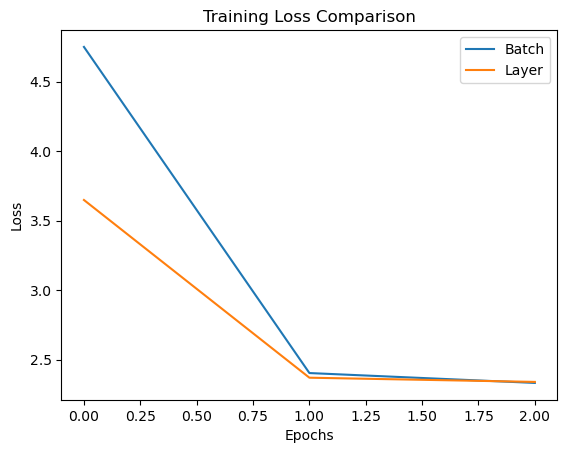

In [5]:
for name,h in results.items():
    plt.plot(h.history['loss'],label=name)

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss Comparison')
plt.legend()
plt.show()

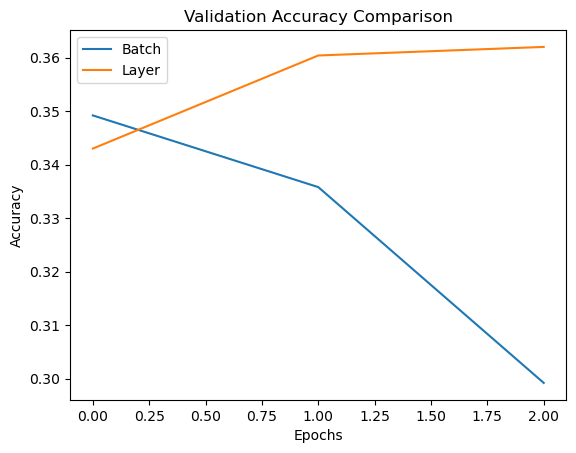

In [6]:
for name,h in results.items():
    plt.plot(h.history['val_accuracy'],label=name)

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Validation Accuracy Comparison')
plt.legend()
plt.show()